# CO₂ adsorption in carbon nanotubes

Automated analysis of molecular-dynamics snapshots: reads every `Nanotube_data/CNT*.xyz` file, determines the nanotube geometry and counts the CO₂ molecules adsorbed inside the tube and on its outer surface (within 7 Å). Results are written to `results.csv`.

In [1]:
import numpy as np
import pandas as pd
import os
import glob
import shutil

**The following function reads an XYZ file and returns a list of (label, x, y, z) tuples.
Handles missing/malformed files.**

In [2]:

def read_xyz(filepath):
 try: 
     with open(filepath,'r') as f:
      lines = f.readlines()
 except FileNotFoundError:
    print(f"Warning file not found: {filepath}")
    return None
     
 n_atoms = int(lines[0].strip())
 atoms = []
 for line in lines[2:]:
        parts = line.split()
        if len(parts) != 4:
          continue
        label = parts[0]
        x, y, z = float(parts[1]), float(parts[2]), float(parts[3])
        atoms.append((label,x,y,z))
 if len(atoms) != n_atoms:
        print(f"Warning: {filepath} declares {n_atoms} atoms but {len(atoms)} were read.")

 return atoms
        
        

 


**The following function separates nanotube atoms (label 'C') from CO2-related atoms.**
**Returns numpy arrays of coordinates for nanotube atoms and Cx atoms**

In [3]:
#We define a function that takes the coordinates of carbon atoms belonging to the nanotube and we store them in a matrix. We do the same for the coord of the carbon atoms of CO2 molecules
def separate_atoms(atoms):
 nanotube_coords = []
 cx_coords = []
 for label, x, y, z in atoms:
    if label == 'C':
        nanotube_coords.append([x,y,z])
    elif label == 'Cx':
        cx_coords.append([x,y,z])
        
 nanotube_coords = np.array(nanotube_coords)
 cx_coords = np.array(cx_coords)
 return nanotube_coords, cx_coords
        
     

**Funtion for verifying that the carbon nanotube axis is the z axis**

In [4]:
def verify_axis_is_z(nanotube_coords):
    
    ##Checks that the nanotube axis is aligned with z by comparing the coordinate ranges. If the axis is z, the z_range (tube length) should
    ##be clearly the largest of the three ranges, while x_range and y_range (both reflecting the tube diameter) should be similar to each other. Returns True if the check passes, False otherwise.
    
    x_range = nanotube_coords[:, 0].max() - nanotube_coords[:, 0].min()
    y_range = nanotube_coords[:, 1].max() - nanotube_coords[:, 1].min()
    z_range = nanotube_coords[:, 2].max() - nanotube_coords[:, 2].min()

    axis_is_z = (z_range > x_range) and (z_range > y_range)

    return axis_is_z, (x_range, y_range, z_range)

**Now we define a function that takes the coordinates of the carbon atoms of the nanotube and compute the radius, diameter, height and volume.**

In [5]:

def compute_nanotube_geometry(nanotube_coords):
 x_center = np.mean(nanotube_coords[:,0])
 y_center = np.mean(nanotube_coords[:,1])

 radial_distances = np.sqrt((nanotube_coords[:,0]-x_center)**2 + (nanotube_coords[:,1]-y_center)**2)
 radius = np.mean(radial_distances)
 diameter = 2*radius

 z_max = np.max(nanotube_coords[:,2])
 z_min = np.min(nanotube_coords[:,2])
 height = z_max - z_min 

 volume = np.pi * radius**2 * height

 return {
        "x_center": x_center,
        "y_center": y_center,
        "radius": radius,
        "diameter": diameter,
        "z_min": z_min,
        "z_max": z_max,
        "height": height,
        "volume": volume,
    }



 

**Now we count the carbon atoms of the molecules that are inside the nanotube or at a distance of less than 7 angstroms**

In [6]:
def classify_co2(cx_coords,geometry):
    x_center = geometry["x_center"]
    y_center = geometry["y_center"]
    radius = geometry["radius"]
    z_min = geometry["z_min"]
    z_max = geometry["z_max"]

    n_inside = 0
    n_outside_adsorbed = 0

    for x, y, z in cx_coords:
        r = np.sqrt((x - x_center) ** 2 + (y - y_center) ** 2)
        z_within_tube = (z_min <= z <= z_max)

        if r < radius and z_within_tube:
            
            n_inside += 1
        elif radius <= r <= radius + 7.0:
            
            n_outside_adsorbed += 1
        

    n_total = n_inside + n_outside_adsorbed
    return n_inside, n_outside_adsorbed, n_total
 

**We define a function that reads one single folder and returns the resuts in a dictionary. This functions includes the rest of the functions defined before.** 
**Processing 4 folders automatically, literally means, running the folder's logic, 4 times, in a loop**

In [7]:
def analyze_system(filepath):
    
    atoms = read_xyz(filepath)

    if atoms is None:
        return None  # the warning was already printed by read_xyz

    nanotube_coords, cx_coords = separate_atoms(atoms)

    if len(nanotube_coords) == 0:
        print(f"Warning: no nanotube atoms found in {filepath}")
        return None


    axis_is_z, ranges = verify_axis_is_z(nanotube_coords)
    if not axis_is_z:
        print(f"Warning: nanotube axis in {filepath} does not appear to be z "
              f"(x_range={ranges[0]:.2f}, y_range={ranges[1]:.2f}, z_range={ranges[2]:.2f}). "
              f"Results may be incorrect.")
        

    geometry = compute_nanotube_geometry(nanotube_coords)
    n_inside, n_outside, n_total = classify_co2(cx_coords, geometry)

    system_name = os.path.splitext(os.path.basename(filepath))[0]

    results = {
        "system": system_name,
        "nanotube_atoms": len(nanotube_coords),
        "co2_molecules": len(cx_coords),
        "radius_A": geometry["radius"],
        "diameter_A": geometry["diameter"],
        "height_A": geometry["height"],
        "volume_A3": geometry["volume"],
        "inside_molecules": n_inside,
        "outside_within_7A": n_outside,
        "total_adsorbed": n_total,
    }

    print("=" * 43)
    print(f"System: {results['system']}")
    print(f"Nanotube atoms: {results['nanotube_atoms']}")
    print(f"CO2 molecules: {results['co2_molecules']}")
    print(f"Radius: {results['radius_A']:.3f} Angstrom")
    print(f"Diameter: {results['diameter_A']:.3f} Angstrom")
    print(f"Height: {results['height_A']:.3f} Angstrom")
    print(f"Volume: {results['volume_A3']:.3f} Angstrom^3")
    print(f"Inside molecules: {results['inside_molecules']}")
    print(f"Outside molecules within 7 A: {results['outside_within_7A']}")
    print(f"Total adsorbed molecules: {results['total_adsorbed']}")
    print("=" * 43)

    return results

**The main function, defined below automatically process all four folders**

In [8]:
def main():
    
    ## Finds all CNT*.xyz files automatically inside 'Nanotube_data', analyzes each one, and saves the combined results to a CSV file.
    
    folders = sorted(glob.glob("Nanotube_data/CNT*.xyz"))

    if not folders:
        print("No CNT*.xyz files found. Check your working directory.")
        return

    all_results = []
    for folder in folders:
        result = analyze_system(folder)
        if result is not None:
            all_results.append(result)

    if not all_results:
        print("No systems were successfully analyzed.")
        return

    df = pd.DataFrame(all_results)
    df.to_csv("results.csv", index=False)
    print("\nResults saved to results.csv")




In [9]:
main()

System: CNT10_150CO2
Nanotube atoms: 200
CO2 molecules: 150
Radius: 3.925 Angstrom
Diameter: 7.850 Angstrom
Height: 19.852 Angstrom
Volume: 960.822 Angstrom^3
Inside molecules: 4
Outside molecules within 7 A: 54
Total adsorbed molecules: 58
System: CNT15_150CO2
Nanotube atoms: 300
CO2 molecules: 150
Radius: 5.874 Angstrom
Diameter: 11.748 Angstrom
Height: 19.852 Angstrom
Volume: 2151.982 Angstrom^3
Inside molecules: 14
Outside molecules within 7 A: 63
Total adsorbed molecules: 77
System: CNT20_150CO2
Nanotube atoms: 480
CO2 molecules: 150
Radius: 7.826 Angstrom
Diameter: 15.652 Angstrom
Height: 24.106 Angstrom
Volume: 4638.122 Angstrom^3
Inside molecules: 32
Outside molecules within 7 A: 67
Total adsorbed molecules: 99
System: CNT5_100CO2
Nanotube atoms: 100
CO2 molecules: 100
Radius: 1.987 Angstrom
Diameter: 3.974 Angstrom
Height: 19.852 Angstrom
Volume: 246.231 Angstrom^3
Inside molecules: 0
Outside molecules within 7 A: 24
Total adsorbed molecules: 24

Results saved to results.csv


**Adsorption as a function of nanotube diameter**

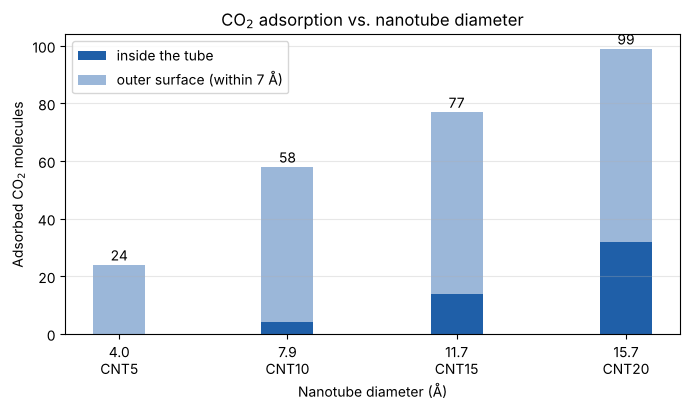

In [10]:
import matplotlib.pyplot as plt

df = pd.read_csv("results.csv").sort_values("diameter_A")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(df["diameter_A"], df["inside_molecules"], width=1.2, color="#1f5fa8", label="inside the tube")
ax.bar(df["diameter_A"], df["outside_within_7A"], width=1.2, bottom=df["inside_molecules"],
       color="#9bb7d9", label="outer surface (within 7 Å)")
for _, row in df.iterrows():
    ax.text(row["diameter_A"], row["total_adsorbed"] + 1.5, int(row["total_adsorbed"]), ha="center")
ax.set_xticks(df["diameter_A"])
ax.set_xticklabels([f"{d:.1f}\n{s.split('_')[0]}" for d, s in zip(df["diameter_A"], df["system"])])
ax.set_xlabel("Nanotube diameter (Å)")
ax.set_ylabel("Adsorbed CO$_2$ molecules")
ax.set_title("CO$_2$ adsorption vs. nanotube diameter")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("adsorption_vs_diameter.png", dpi=150)
plt.show()